# Laya V3.6 — Replace ALL Full + Sliding Attention: Two Native-SDPA Architectures

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vtavakkoli/TinyCeNN-LM/blob/main/notebooks/Laya_V36_AllAttention_RoutedAndSliding_NativeSDPA_Colab.ipynb)

## Research question

Can we replace **every attention layer**, both original **full attention** and **sliding-window attention**, with either:

**A. Query-Routed Sparse SDPA** — the V3.4/V3.5 five-prototype block router, exact 256-position local window and eight query-selected remote original keys, followed by **ONE unified native PyTorch SDPA** over the collected original K/V tokens.

**B. All-Sliding Native SDPA** — replace **all** original full and sliding layers with one native PyTorch SDPA operation using a configurable 128/256/384/512-token band mask (default 256).

Both variants reuse frozen pretrained Wqkv, RoPE, Wo and output dropout of **each** attention layer; feedforward, layer normalization and classification heads are unchanged. Nothing is retrained. Original full-vs-sliding layer types are discovered from the pretrained teacher; no original attention module is left in either replacement model. Evaluation includes exact SDPA preflight, original full/sliding isolated comparison, matched held-out teacher decision agreement, gold accuracy, JS, and warmed GPU inference latency.

**Important:** Native SDPA is not automatically faster under custom masks or per-query gathered K/V. V3.5 achieved 97.5% teacher agreement and 84% gold accuracy versus 86% teacher on 200 decisions with ten *full* layers replaced, but was slower than native. V3.6 replaces **all layers**, including the original sliding layers, so its quality is unknown until Colab executes.

**Data protocol:** 80 training cases not used for optimization, 80 case-disjoint PROBE cases, 80 case-disjoint AUDIT cases, all from the dataset TRAIN split; official TEST unused. Default 200 held-out decisions per variant. Probe-only optional sliding-window selection, no audit selection. No model or checkpoint overwritten. Stop/go: teacher agreement ≥95%, gold drop ≤1 percentage point, representative isolated cosine ≥.95, and real model speedup >1×.


In [1]:
#@title 1. Install pinned Laya dependencies and check GPU
%pip -q install "transformers==4.57.6" "datasets>=2.20" "huggingface_hub>=0.25,<1" "safetensors>=0.4"
%pip -q install -U "git+https://github.com/vtavakkoli/TinyCeNN-LM.git@main"
import torch
if not torch.cuda.is_available():
    raise RuntimeError("Select Colab Runtime > Change runtime type > GPU.")
print("Torch",torch.__version__,"CUDA",torch.version.cuda,"GPU",torch.cuda.get_device_name(0))


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 66.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Torch 2.11.0+cu130 CUDA 13.0 GPU Tesla T4


In [2]:
#@title 2. Imports, frozen Laya teacher and experiment configuration
from pathlib import Path
import copy, json, math, random, time
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from datasets import load_dataset
from huggingface_hub import snapshot_download
from transformers import AutoTokenizer

from tinycenn_lm.decision_v25 import layer_kinds, MultiscaleCeNN
from tinycenn_lm.standalone_decision import (
    QTYPES, build_checkpoint_model, build_sequence,
    collate_items, normalize_question,
)
from tinycenn_lm.decision_training import require_finite

SEED = 2036
SOURCE_MODEL = "convaiinnovations/laya-typed-decisions" #@param {type:"string"}
LAYER = 15 #@param {type:"integer"}
TARGET_LAYERS = (LAYER,)
TRAIN_CASES = 80 #@param {type:"integer"}
DEV_CASES = 160 #@param {type:"integer"}
MAX_LEN = 512 #@param {type:"integer"}
BATCH = 3 #@param {type:"integer"}
STEPS = 400 #@param {type:"integer"}
REFINE_STEPS = 1200 #@param {type:"integer"}
REFINE_TOP_K = 2 #@param {type:"integer"}
TRAIN_CACHE_BATCHES = 1 #@param {type:"integer"}
PROBE_CACHE_BATCHES = 2 #@param {type:"integer"}
AUDIT_CACHE_BATCHES = 2 #@param {type:"integer"}
CHECK_EVERY = 100 #@param {type:"integer"}
OUTPUT_DIR = Path("/content/Laya_V36_AllAttention_NativeSDPA")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert DEV_CASES >= 4 and TRAIN_CACHE_BATCHES > 0
assert REFINE_TOP_K >= 1 and TRAIN_CACHE_BATCHES > 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("Use a CUDA GPU runtime in Google Colab.")
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda")
amp_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16

source_dir = Path(snapshot_download(
    SOURCE_MODEL, allow_patterns=[
        "rl_agent_config.json", "model.safetensors", "encoder/*", "tokenizer/*",
    ],
))
teacher, source_cfg = build_checkpoint_model(source_dir)
student_eval, _ = build_checkpoint_model(source_dir)
tokenizer = AutoTokenizer.from_pretrained(str(source_dir / "tokenizer"))
teacher.to(device).eval().requires_grad_(False)
student_eval.to(device).eval().requires_grad_(False)
teacher.encoder.config.reference_compile = False
student_eval.encoder.config.reference_compile = False

kinds = layer_kinds(teacher.encoder)
full_layers = [i for i, kind in enumerate(kinds) if kind == "full_attention"]
assert LAYER in full_layers, (LAYER, full_layers)
print("GPU:", torch.cuda.get_device_name(0), "AMP:", amp_dtype)
print("Source:", SOURCE_MODEL)
print("Target:", LAYER, "all full attention layers:", full_layers)
#@title V3.6 two-variant controls
BLOCK_SIZE=16
ROUTE_BLOCKS=8
REMOTE_K=8
LOCAL_LEFT=127
LOCAL_RIGHT=128
QUERY_CHUNK=16 #@param {type:"integer"}
SLIDING_WINDOW=256 #@param {type:"integer"}
AUDIT_DECISIONS=200 #@param {type:"integer"}
PROBE_DECISIONS=60 #@param {type:"integer"}
RUN_BOTH_VARIANTS=True #@param {type:"boolean"}
RUN_WINDOW_SWEEP=False #@param {type:"boolean"}
SLIDING_SWEEP=(128,256,384,512)
PROFILE_ALL_LAYERS=False #@param {type:"boolean"}
BENCHMARK_REPEATS=8 #@param {type:"integer"}
assert BLOCK_SIZE==16 and ROUTE_BLOCKS==8 and REMOTE_K==8
assert QUERY_CHUNK>=1 and SLIDING_WINDOW>=1
print("Original kinds:",dict((k,kinds.count(k)) for k in set(kinds)))
print("Frozen native-SDPA attention variants; no training.")


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/337 [00:00<?, ?B/s]

rl_agent_config.json:   0%|          | 0.00/847 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/843M [00:00<?, ?B/s]

GPU: Tesla T4 AMP: torch.float16
Source: convaiinnovations/laya-typed-decisions
Target: 15 all full attention layers: [0, 3, 6, 9, 12, 15, 18, 21, 24, 27]
Original kinds: {'full_attention': 10, 'sliding_attention': 18}
Frozen native-SDPA attention variants; no training.


In [3]:
#@title 3. Leak-free train/dev data and teacher I/O helpers
def _jsonish(x):
    if isinstance(x, str):
        try:
            return json.loads(x)
        except Exception:
            return x
    return x

def _canon_label(x):
    s = str(x).strip().lower()
    try:
        v = float(s)
        if math.isfinite(v) and v.is_integer():
            return str(int(v))
    except Exception:
        pass
    return s

def _gold_metadata(q, gold_answer):
    if not isinstance(gold_answer, dict):
        raise ValueError("missing gold answer")
    probs_raw = _jsonish(gold_answer.get("probabilities", {}))
    if not isinstance(probs_raw, dict) or len(probs_raw) < 2:
        raise ValueError("gold probabilities missing or malformed")

    gold_keys = [str(k) for k in probs_raw.keys()]
    if q["t"] == "choice":
        labels = [str(k) for k in q["crit"].keys()]
    elif q["t"] == "noul":
        labels = ["false", "true"]
    else:
        labels = list(gold_keys)
        if all(_canon_label(k).lstrip("-").isdigit() for k in labels):
            labels = sorted(labels, key=lambda k: int(_canon_label(k)))

    lookup = {_canon_label(k): float(v) for k, v in probs_raw.items()}
    if len(labels) != len(gold_keys) or any(_canon_label(k) not in lookup for k in labels):
        raise ValueError("Gold labels do not match encoded option order")

    gold_probs = np.asarray([lookup[_canon_label(k)] for k in labels], dtype=np.float64)
    gold_probs = np.clip(gold_probs, 0.0, None)
    if not np.isfinite(gold_probs).all() or gold_probs.sum() <= 0:
        raise ValueError("invalid gold probability vector")
    gold_probs /= gold_probs.sum()

    gold_label = _canon_label(gold_answer.get("label", labels[int(gold_probs.argmax())]))
    canon_labels = [_canon_label(k) for k in labels]
    if gold_label not in canon_labels:
        raise ValueError(f"gold label {gold_label!r} not in {labels!r}")
    return labels, gold_probs.tolist(), canon_labels.index(gold_label)

def make_items_from_rows(rows, seed, shuffle_items):
    out = []
    head_max_len = int(source_cfg.get("head_max_len", 192))
    for row in rows:
        state = _jsonish(row["state"])
        questions = _jsonish(row["questions"])
        gold = _jsonish(row["gold"])
        case_id = str(row.get("id", ""))
        workflow = str(row.get("workflow", "unknown"))
        state_text = state if isinstance(state, str) else json.dumps(state, ensure_ascii=False)
        state_ids = tokenizer(
            state_text.replace(tokenizer.mask_token, " "),
            add_special_tokens=False,
        )["input_ids"]

        for qid, qdef in questions.items():
            q = normalize_question(qdef)
            ids, markers = build_sequence(
                tokenizer,
                state,
                q,
                max_len=min(MAX_LEN, int(source_cfg.get("max_len", MAX_LEN))),
                head_max_len=head_max_len,
                truncate_left=isinstance(state, list),
                state_ids=state_ids,
            )
            if len(markers) < 2:
                continue
            labels, gold_probs, gold_index = _gold_metadata(q, gold[qid])
            if len(labels) != len(markers):
                raise ValueError(
                    f"{case_id}/{qid}: {len(markers)} markers vs {len(labels)} gold labels"
                )
            out.append({
                "ids": ids,
                "markers": markers,
                "qtype": QTYPES[q["t"]],
                "qtype_name": q["t"],
                "qid": str(qid),
                "case_id": case_id,
                "workflow": workflow,
                "labels": labels,
                "gold_probs": gold_probs,
                "gold_index": int(gold_index),
            })
    if shuffle_items:
        random.Random(seed).shuffle(out)
    return out

rows = list(load_dataset("LocalLLaMA/typed-decisions", "all", split="train"))
rng = random.Random(SEED)
rng.shuffle(rows)
assert TRAIN_CASES + DEV_CASES <= len(rows)
train_rows = rows[:TRAIN_CASES]
dev_rows = rows[TRAIN_CASES:TRAIN_CASES + DEV_CASES]
train_items = make_items_from_rows(train_rows, SEED, True)
# Split at the CASE level before creating multiple question items per case.
probe_rows = dev_rows[:len(dev_rows) // 2]
audit_rows = dev_rows[len(dev_rows) // 2:]
probe_items = make_items_from_rows(probe_rows, SEED + 1, True)
audit_items = make_items_from_rows(audit_rows, SEED + 2, True)
dev_items = probe_items # backward-compatible alias for training helper use
assert train_items and probe_items and audit_items
assert {str(r["id"]) for r in probe_rows}.isdisjoint({str(r["id"]) for r in audit_rows})

def direct_batch(selected):
    b = collate_items(selected, int(tokenizer.pad_token_id))
    return {k: v.to(device) for k, v in b.items()}

def batch(items, offset, n=BATCH):
    selected = [items[(offset + i) % len(items)] for i in range(n)]
    return direct_batch(selected)

def _snapshot_attention_argument(value):
    """Retain the exact forward inputs for ModernBERT SDPA replay/timing."""
    if torch.is_tensor(value):
        return value.detach()
    if isinstance(value, tuple):
        return tuple(_snapshot_attention_argument(v) for v in value)
    if isinstance(value, list):
        return [_snapshot_attention_argument(v) for v in value]
    if isinstance(value, dict):
        return {k: _snapshot_attention_argument(v) for k, v in value.items()}
    return value

def _attention_output_tensor(result):
    """ModernBERT variants return either tensor or (tensor, optional weights)."""
    return result[0] if isinstance(result, (tuple, list)) else result

def attn_io(model, layer_idx, b):
    layer = model.encoder.layers[layer_idx]
    got = {}
    def pre(mod, args, kwargs):
        # The encoder passes more than x/position_embeddings/attention_mask:
        # position_ids, sliding_window_mask and optional flags are required by
        # transformers 4.57.6 SDPA. Never infer these for benchmarking.
        got["call_args"] = _snapshot_attention_argument(tuple(args))
        got["call_kwargs"] = _snapshot_attention_argument(dict(kwargs))
        got["x"] = args[0].detach()
        got["pos"] = _snapshot_attention_argument(kwargs.get("position_embeddings"))
        got["mask"] = _snapshot_attention_argument(kwargs.get("attention_mask"))
    def post(mod, args, kwargs, out):
        got["y"] = _attention_output_tensor(out).detach()
    h1 = layer.attn.register_forward_pre_hook(pre, with_kwargs=True)
    h2 = layer.attn.register_forward_hook(post, with_kwargs=True)
    try:
        with torch.no_grad(), torch.autocast(device_type="cuda", dtype=amp_dtype):
            model(**b)
    finally:
        h1.remove()
        h2.remove()
    return got

def cache_teacher_io(layer_idx, items, batches, offset=0):
    cache = []
    for i in range(batches):
        b = batch(items, offset + i * BATCH, BATCH)
        got = attn_io(teacher, layer_idx, b)
        cache.append({
            "x": got["x"],
            "pos": got["pos"],
            "mask": got["mask"],
            "call_args": got["call_args"],
            "call_kwargs": got["call_kwargs"],
            "y": got["y"],
            "valid": b["attention_mask"].bool(),
        })
    return cache

def local_metrics_from_cache(repl, cache):
    repl.eval()
    diff_sum = power_sum = cos_sum = 0.0
    tokens = 0
    with torch.no_grad():
        for entry in cache:
            with torch.autocast(device_type="cuda", dtype=amp_dtype):
                pred, _ = repl(
                    entry["x"],
                    position_ids=entry["call_kwargs"].get("position_ids"),
                    attention_mask=entry["mask"],
                )
            require_finite(pred, "V3.6 local probe")
            valid = entry["valid"]
            m = valid[:, :, None].float()
            d = pred.shape[-1]
            diff_sum += float((((pred.float() - entry["y"].float()) ** 2) * m).sum())
            power_sum += float(((entry["y"].float() ** 2) * m).sum())
            count = int(valid.sum())
            cos_sum += float(
                F.cosine_similarity(
                    pred.float()[valid],
                    entry["y"].float()[valid],
                    dim=-1,
                ).sum()
            )
            tokens += count
    nmse = diff_sum / max(power_sum, 1e-8)
    cosine = cos_sum / max(tokens, 1)
    score = nmse + 1.10 * (1.0 - cosine)
    return {"nmse": nmse, "cosine": cosine, "score": score, "tokens": tokens}

print("train/probe/audit decisions:", len(train_items), len(probe_items), len(audit_items))
print("unique train/probe/audit cases:", len(train_rows), len(probe_rows), len(audit_rows))
assert len(probe_items) >= PROBE_CACHE_BATCHES * BATCH, "Increase DEV_CASES or reduce PROBE_CACHE_BATCHES"
assert len(audit_items) >= AUDIT_CACHE_BATCHES * BATCH, "Increase DEV_CASES or reduce AUDIT_CACHE_BATCHES"
print("official test remains untouched")


README.md: 0.00B [00:00, ?B/s]

all/train-00000-of-00001.parquet:   0%|          | 0.00/599k [00:00<?, ?B/s]

all/test-00000-of-00001.parquet:   0%|          | 0.00/222k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1200 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/400 [00:00<?, ? examples/s]

train/probe/audit decisions: 400 400 400
unique train/probe/audit cases: 80 80 80
official test remains untouched


In [4]:
#@title 4. Query-routed native SDPA and all-sliding native SDPA modules
from transformers.models.modernbert.modeling_modernbert import apply_rotary_pos_emb
from tinycenn_lm.laya_lab.core import _valid_tokens

def gather_native_mask(mask,B,H,T,start,stop,indices):
    if mask is None or mask.ndim==2:
        return None
    if mask.ndim!=4 or mask.shape[-2:]!=(T,T):
        raise ValueError(f"Unsupported native attention mask: {mask.shape}")
    return mask[:,:,start:stop,:].expand(B,H,stop-start,T).gather(-1,indices)

def route_selected_indices(q,k,valid,attention_mask=None):
    """V3.4 query-conditioned five-prototype, 8-block routing.

    Yield one set of unique local+remote original key positions per query,
    without computing the full query-to-key attention score matrix.
    """
    B,H,T,D=q.shape
    G=(T+15)//16
    kp=F.pad(k,(0,0,0,G*16-T)).float().reshape(B,H,G,16,D)
    vp=F.pad(valid,(0,G*16-T),value=False).reshape(B,G,16)
    counts=vp.sum(-1).clamp_min(1)
    av=(kp*vp[:,None,:,:,None]).sum(3)/counts[:,None,:,None]
    mid=((counts-1)//2)[:,None,:].expand(B,H,G)
    last=(counts-1)[:,None,:].expand(B,H,G)
    high=kp.square().sum(-1).masked_fill(~vp[:,None,:,:],-1e30).argmax(3)
    def one(j):
        return kp.gather(3,j[...,None,None].expand(B,H,G,1,D)).squeeze(3)
    proto=torch.stack((av,kp[:,:,:,0],one(mid),one(last),one(high)),dim=3)
    has_keys=vp.any(-1)
    gg=torch.arange(G,device=q.device)
    block_start=gg*16
    block_end=torch.clamp(block_start+15,max=T-1)
    ib=torch.arange(B,device=q.device)[:,None,None,None]
    ih=torch.arange(H,device=q.device)[None,:,None,None]
    for start in range(0,T,QUERY_CHUNK):
        stop=min(start+QUERY_CHUNK,T)
        C=stop-start
        qs=q[:,:,start:stop].float()
        pos=torch.arange(start,stop,device=q.device)
        with torch.autocast(device_type=q.device.type,enabled=False):
            salience=torch.einsum(
                "bhcd,bhgrd->bhcgr",qs.float(),proto.float()
            ).amax(-1)/math.sqrt(D)
        far=(block_start[None,:]<pos[:,None]-LOCAL_LEFT) | (
            block_end[None,:]>pos[:,None]+LOCAL_RIGHT
        )
        salience=salience.masked_fill(
            ~(far[None,None,:,:]&has_keys[:,None,None,:]),-1e9
        )
        chosen=torch.topk(salience,k=min(ROUTE_BLOCKS,G),dim=-1).indices
        candidate=(chosen[...,None]*16+
                   torch.arange(16,device=q.device)).reshape(B,H,C,-1)
        inrange=candidate<T
        candidate=candidate.clamp(max=T-1)
        can_use=valid[:,None,None,:].expand(B,H,C,T).gather(-1,candidate)
        can_use=can_use & inrange & (
            (candidate<pos[None,None,:,None]-LOCAL_LEFT) |
            (candidate>pos[None,None,:,None]+LOCAL_RIGHT)
        )
        origin_mask=gather_native_mask(
            attention_mask,B,H,T,start,stop,candidate
        )
        if origin_mask is not None:
            can_use=can_use & (origin_mask if origin_mask.dtype==torch.bool
                                else origin_mask.float()>-1e4)
        candidate_k=k[ib,ih,candidate,:].float()
        logits=(qs[:,:,:,None,:]*candidate_k).sum(-1)/math.sqrt(D)
        if origin_mask is not None and origin_mask.dtype!=torch.bool:
            logits=logits+origin_mask.float()
        logits=logits.masked_fill(~can_use,-1e9)
        selected=torch.topk(logits,k=min(REMOTE_K,logits.shape[-1]),dim=-1).indices
        remote=candidate.gather(-1,selected)
        remote_allowed=can_use.gather(-1,selected)
        offsets=torch.arange(-LOCAL_LEFT,LOCAL_RIGHT+1,device=q.device)
        raw_local=pos[:,None]+offsets[None,:]
        local_valid=(raw_local>=0)&(raw_local<T)
        local=raw_local.clamp(0,T-1)[None,None,:,:].expand(B,H,C,256)
        indices=torch.cat((local,remote),dim=-1)
        allowed=torch.cat(
            (local_valid[None,None,:,:].expand(B,H,C,256),remote_allowed),
            dim=-1
        )
        allowed=allowed & valid[:,None,None,:].expand(B,H,C,T).gather(-1,indices)
        native_mask=gather_native_mask(attention_mask,B,H,T,start,stop,indices)
        if native_mask is not None:
            allowed=allowed & (native_mask if native_mask.dtype==torch.bool
                                else native_mask.float()>-1e4)
        yield start,stop,indices,allowed,native_mask

def routed_native_sdpa(q,k,v,valid,mask=None):
    """Actual F.scaled_dot_product_attention on unified selected K/V."""
    B,H,T,D=q.shape
    ib=torch.arange(B,device=q.device)[:,None,None,None]
    ih=torch.arange(H,device=q.device)[None,:,None,None]
    answers=[]
    for start,stop,indices,allowed,existing_bias in route_selected_indices(
        q,k,valid,mask
    ):
        C=stop-start
        S=indices.shape[-1]
        qsel=q[:,:,start:stop,:].contiguous()
        ksel=k[ib,ih,indices,:].contiguous()
        vsel=v[ib,ih,indices,:].contiguous()
        sdpa_mask=allowed
        if existing_bias is not None and existing_bias.dtype!=torch.bool:
            sdpa_mask=torch.where(
                allowed,existing_bias.to(q.dtype),
                torch.finfo(q.dtype).min
            )
        value=F.scaled_dot_product_attention(
            qsel.reshape(B*H*C,1,D),
            ksel.reshape(B*H*C,S,D),
            vsel.reshape(B*H*C,S,D),
            attn_mask=sdpa_mask.reshape(B*H*C,1,S),
            dropout_p=0.0
        ).reshape(B,H,C,D)
        answers.append(value*valid[:,None,start:stop,None].to(value.dtype))
    return torch.cat(answers,dim=2)

def sliding_native_sdpa(q,k,v,valid,mask=None,window=256):
    """Standard native PyTorch SDPA over a banded full [T,T] mask."""
    B,H,T,D=q.shape
    left=(window-1)//2
    right=window-1-left
    t=torch.arange(T,device=q.device)
    distances=t[None,:]-t[:,None]
    within=(distances>=-left)&(distances<=right)
    allowed=within[None,None,:,:] & valid[:,None,None,:]
    if mask is not None and mask.ndim==4:
        if mask.shape[-2:]!=(T,T):
            raise ValueError(f"Bad source mask shape {mask.shape}")
        allowed=allowed & (mask if mask.dtype==torch.bool
                           else mask.float()>-1e4)
    elif mask is not None and mask.ndim!=2:
        raise ValueError(f"Unsupported mask rank {mask.ndim}")
    sdpa_mask=allowed
    if mask is not None and mask.ndim==4 and mask.dtype!=torch.bool:
        sdpa_mask=torch.where(
            allowed,mask.to(q.dtype),torch.finfo(q.dtype).min
        )
    out=F.scaled_dot_product_attention(
        q,k,v,attn_mask=sdpa_mask,dropout_p=0.0
    )
    return out*valid[:,None,:,None].to(out.dtype)

class ReplacedSDPAAttention(nn.Module):
    """Drop-in attention for both native full and native sliding layers."""
    def __init__(self,original,mode,window=256):
        super().__init__()
        assert mode in ("routed_sdpa","sliding_sdpa")
        self.config=original.config
        self.num_heads=original.num_heads
        self.head_dim=original.head_dim
        self.hidden_size=int(original.config.hidden_size)
        self.mode=mode
        self.window=window
        self.Wqkv=copy.deepcopy(original.Wqkv).requires_grad_(False)
        self.Wo=copy.deepcopy(original.Wo).requires_grad_(False)
        self.rotary_emb=copy.deepcopy(original.rotary_emb).requires_grad_(False)
        self.out_drop=copy.deepcopy(original.out_drop).requires_grad_(False)
        self.eval()
    def forward(self,hidden_states,attention_mask=None,position_ids=None,
                position_embeddings=None,sliding_window_mask=None,**kwargs):
        B,T,D=hidden_states.shape
        if position_ids is None:
            position_ids=torch.arange(T,device=hidden_states.device)[None,:]
        qkv=self.Wqkv(hidden_states).view(B,T,3,self.num_heads,self.head_dim)
        cos,sin=self.rotary_emb(qkv,position_ids=position_ids)
        q,k,v=qkv.transpose(3,1).unbind(dim=2)
        q,k=apply_rotary_pos_emb(q,k,cos,sin)
        valid=_valid_tokens(attention_mask,hidden_states)
        core=(routed_native_sdpa(q,k,v,valid,attention_mask)
              if self.mode=="routed_sdpa"
              else sliding_native_sdpa(q,k,v,valid,attention_mask,self.window))
        projected=self.Wo(
            core.transpose(1,2).contiguous().reshape(B,T,D)
        )
        return self.out_drop(projected),None

ALL_LAYERS=list(range(len(kinds)))
FULL_LAYERS=[i for i,v in enumerate(kinds) if v=="full_attention"]
SLIDING_LAYERS=[i for i,v in enumerate(kinds) if v!="full_attention"]
assert FULL_LAYERS and SLIDING_LAYERS
def make_replacement(idx,mode,window=SLIDING_WINDOW):
    return ReplacedSDPAAttention(
        teacher.encoder.layers[idx].attn,mode,window
    ).to(device).eval().requires_grad_(False)
def replace_all_layers(model,mode,window=SLIDING_WINDOW):
    assert len(model.encoder.layers)==len(ALL_LAYERS)
    for idx in ALL_LAYERS:
        model.encoder.layers[idx].attn=make_replacement(idx,mode,window)
    assert all(isinstance(model.encoder.layers[idx].attn,ReplacedSDPAAttention)
               for idx in ALL_LAYERS)
    return model.eval().requires_grad_(False)
print("All-layer target:",len(ALL_LAYERS),
      "original full",len(FULL_LAYERS),"original sliding",len(SLIDING_LAYERS))


All-layer target: 28 original full 10 original sliding 18


In [5]:
#@title 5. GPU numerical preflight: short native parity, longer selected attention, padding
def masked_metric(actual,expected,valid):
    use=valid[:,None,:].expand(actual.shape[:3])
    a=actual.float()[use]
    b=expected.float()[use]
    return (float((a-b).abs().max()),
            float(F.cosine_similarity(a,b,dim=-1).mean()))
for T in (9,64,128):
    torch.manual_seed(T+2036)
    q=torch.randn(1,2,T,32,device=device,dtype=amp_dtype)
    k=torch.randn_like(q);v=torch.randn_like(q)
    valid=torch.ones(1,T,dtype=torch.bool,device=device)
    valid[:,-max(1,T//10):]=False
    for mask in (
        valid[:,None,None,:].expand(1,1,T,T).contiguous(),
        torch.where(valid[:,None,None,:].expand(1,1,T,T),
                    torch.tensor(0.0,device=device),
                    torch.tensor(-10000.0,device=device)).contiguous()
    ):
        with torch.inference_mode(),torch.autocast(device_type="cuda",dtype=amp_dtype):
            qmask=mask if mask.dtype==torch.bool else mask.to(q.dtype)
            truth=F.scaled_dot_product_attention(q,k,v,attn_mask=qmask)
            truth=truth*valid[:,None,:,None]
            routed=routed_native_sdpa(q,k,v,valid,mask)
            sliding=sliding_native_sdpa(q,k,v,valid,mask,window=256)
        for name,pred in (("routed",routed),("sliding",sliding)):
            diff,cos=masked_metric(pred,truth,valid)
            assert diff<.015 and cos>.999,(T,name,str(mask.dtype),diff,cos)
            print(f"T={T} {name} vs native, mask={mask.dtype} PASS Δ={diff:.5g} cos={cos:.7f}")
# The routed approximation must use ONE correctly normalized softmax.
# Compare native SDPA output to independent explicit probability math using
# precisely the SAME selected original K/V set, including float bias.
for T in (256,320,512):
    torch.manual_seed(T+3036)
    q=torch.randn(1,2,T,32,device=device,dtype=amp_dtype)
    k=torch.randn_like(q);v=torch.randn_like(q)
    valid=torch.ones(1,T,dtype=torch.bool,device=device)
    valid[:,-min(41,T//8):]=False
    mask=valid.long() if T==320 else torch.where(
        valid[:,None,None,:].expand(1,1,T,T),
        torch.tensor(0.,device=device),
        torch.tensor(-10000.,device=device)
    ).contiguous()
    with torch.inference_mode(),torch.autocast(device_type="cuda",dtype=amp_dtype):
        out=routed_native_sdpa(q,k,v,valid,mask)
        ref_chunks=[]
        bindex=torch.arange(1,device=device)[:,None,None,None]
        hindex=torch.arange(2,device=device)[None,:,None,None]
        for start,stop,ids,allowed,bias in route_selected_indices(q,k,valid,mask):
            qq=q[:,:,start:stop].float()
            kk=k[bindex,hindex,ids].float()
            vv=v[bindex,hindex,ids].float()
            logits=(qq[:,:,:,None,:]*kk).sum(-1)/math.sqrt(32)
            if bias is not None and bias.dtype!=torch.bool:
                logits+=bias.float()
            logits=logits.masked_fill(~allowed,-1e9)
            p=torch.softmax(logits,dim=-1)
            ref_chunks.append((p[...,None]*vv).sum(-2)*valid[:,None,start:stop,None])
        reference=torch.cat(ref_chunks,dim=2)
    diff,cos=masked_metric(out,reference,valid)
    assert diff<.02 and cos>.999,(T,diff,cos)
    print(f"T={T} routed native SDPA vs independent selected-key softmax PASS Δ={diff:.5g}, cos={cos:.7f}")
# Pretrained attention replay: verify native kwargs for one full and sliding layer.
for idx in (FULL_LAYERS[0],SLIDING_LAYERS[0]):
    entry=attn_io(teacher,idx,batch(probe_items,0,BATCH))
    with torch.inference_mode(),torch.autocast(device_type="cuda",dtype=amp_dtype):
        replay=_attention_output_tensor(
            teacher.encoder.layers[idx].attn(*entry["call_args"],**entry["call_kwargs"])
        )
    diff=float((replay.float()-entry["y"].float()).abs().max())
    assert diff<1e-2,(idx,diff)
    print("Original teacher replay layer",idx,"PASS",diff)
# Same-shape randomized padded K/V must never change valid-token results.
for mode in ("routed_sdpa","sliding_sdpa"):
    layer=make_replacement(FULL_LAYERS[0],mode)
    x=torch.randn(1,320,layer.hidden_size,device=device)
    padding=torch.zeros(1,320,dtype=torch.long,device=device)
    padding[:,:279]=1
    original=x.clone();original[:,279:]=0
    corrupted=x.clone();corrupted[:,279:]=torch.randn_like(corrupted[:,279:])*5
    with torch.inference_mode(),torch.autocast(device_type="cuda",dtype=amp_dtype):
        p1=layer(original,attention_mask=padding)[0][:,:279]
        p2=layer(corrupted,attention_mask=padding)[0][:,:279]
    maxdiff=float((p1.float()-p2.float()).abs().max())
    assert maxdiff<.02,(mode,maxdiff)
    print("Real pretrained padded-token invariance",mode,"PASS",maxdiff)
    del layer
torch.cuda.empty_cache()


T=9 routed vs native, mask=torch.bool PASS Δ=0.00048828 cos=1.0000000
T=9 sliding vs native, mask=torch.bool PASS Δ=0 cos=1.0000000
T=9 routed vs native, mask=torch.float32 PASS Δ=0.00048828 cos=1.0000000
T=9 sliding vs native, mask=torch.float32 PASS Δ=0 cos=1.0000000
T=64 routed vs native, mask=torch.bool PASS Δ=0.00048828 cos=1.0000000
T=64 sliding vs native, mask=torch.bool PASS Δ=0 cos=1.0000000
T=64 routed vs native, mask=torch.float32 PASS Δ=0.00048828 cos=1.0000000
T=64 sliding vs native, mask=torch.float32 PASS Δ=0 cos=1.0000000
T=128 routed vs native, mask=torch.bool PASS Δ=0.00048828 cos=1.0000000
T=128 sliding vs native, mask=torch.bool PASS Δ=0 cos=1.0000000
T=128 routed vs native, mask=torch.float32 PASS Δ=0.00048828 cos=1.0000000
T=128 sliding vs native, mask=torch.float32 PASS Δ=0 cos=1.0000000
T=256 routed native SDPA vs independent selected-key softmax PASS Δ=0.00020444, cos=1.0000000
T=320 routed native SDPA vs independent selected-key softmax PASS Δ=0.00022113, cos=

In [6]:
#@title 6. Matched teacher agreement and CUDA event timing
@torch.inference_mode()
def evaluate(model,items,limit=AUDIT_DECISIONS):
    count=matches=t_gold=s_gold=0
    total_js=0.0
    max_items=min(len(items),limit)
    for start in range(0,max_items,BATCH):
        chosen=items[start:min(start+BATCH,max_items)]
        data=direct_batch(chosen)
        with torch.autocast(device_type="cuda",dtype=amp_dtype):
            native,_=teacher(**data)
            student,_=model(**data)
        good=data["marker_mask"].bool()
        t=torch.softmax(native.float().masked_fill(~good,-1e9),dim=-1)
        s=torch.softmax(student.float().masked_fill(~good,-1e9),dim=-1)
        labels=torch.tensor([x["gold_index"] for x in chosen],device=device)
        count+=len(chosen)
        matches+=int((t.argmax(-1)==s.argmax(-1)).sum())
        t_gold+=int((t.argmax(-1)==labels).sum())
        s_gold+=int((s.argmax(-1)==labels).sum())
        m=(t+s)*.5
        total_js+=float(.5*((t*(t.clamp_min(1e-8).log()-m.clamp_min(1e-8).log())).sum(-1)+
                                (s*(s.clamp_min(1e-8).log()-m.clamp_min(1e-8).log())).sum(-1)).sum())
    return dict(decisions=count,teacher_agreement=matches/max(count,1),
                teacher_gold_accuracy=t_gold/max(count,1),
                student_gold_accuracy=s_gold/max(count,1),
                gold_accuracy_drop=(t_gold-s_gold)/max(count,1),
                mean_js=total_js/max(count,1))
@torch.inference_mode()
def elapsed_ms(fn,repeats=BENCHMARK_REPEATS):
    with torch.autocast(device_type="cuda",dtype=amp_dtype):
        for _ in range(3):fn()
        torch.cuda.synchronize()
        ticks=[]
        for _ in range(repeats):
            a=torch.cuda.Event(enable_timing=True)
            b=torch.cuda.Event(enable_timing=True)
            a.record();fn();b.record();b.synchronize()
            ticks.append(a.elapsed_time(b))
    return float(np.median(ticks))
@torch.inference_mode()
def local_metrics(candidate,entries):
    loss=denom=csum=0.0
    count=0
    for entry in entries:
        with torch.autocast(device_type="cuda",dtype=amp_dtype):
            y,_=candidate(
                entry["x"],attention_mask=entry["mask"],
                position_ids=entry["call_kwargs"].get("position_ids")
            )
        good=entry["valid"]
        a=y.float()[good];b=entry["y"].float()[good]
        loss+=float((a-b).square().sum());denom+=float(b.square().sum())
        csum+=float(F.cosine_similarity(a,b,dim=-1).sum())
        count+=int(good.sum())
    return dict(cosine=csum/max(count,1),nmse=loss/max(1e-8,denom))
print("Untouched native baseline:",evaluate(student_eval,audit_items))


Untouched native baseline: {'decisions': 200, 'teacher_agreement': 1.0, 'teacher_gold_accuracy': 0.825, 'student_gold_accuracy': 0.825, 'gold_accuracy_drop': 0.0, 'mean_js': 0.0}


In [7]:
#@title 7. Optional sliding-window search (PROBE ONLY, no audit data)
selected_window=SLIDING_WINDOW
window_probe={}
if RUN_WINDOW_SWEEP:
    for win in SLIDING_SWEEP:
        model,_=build_checkpoint_model(source_dir)
        model.to(device).eval().requires_grad_(False)
        model.encoder.config.reference_compile=False
        replace_all_layers(model,"sliding_sdpa",window=win)
        quality=evaluate(model,probe_items,PROBE_DECISIONS)
        window_probe[str(win)]=quality
        print("Probe sliding window",win,quality)
        del model
        torch.cuda.empty_cache()
    selected_window=max(
        SLIDING_SWEEP,
        key=lambda w:(window_probe[str(w)]["teacher_agreement"],
                      -window_probe[str(w)]["mean_js"])
    )
    print("Selected on probe only:",selected_window)
else:
    print("Fixed sliding window:",selected_window)


Fixed sliding window: 256


In [8]:
#@title 8. Isolated full AND sliding layer accuracy and GPU timings
selected_layers=(ALL_LAYERS if PROFILE_ALL_LAYERS else sorted(set([
    FULL_LAYERS[0],FULL_LAYERS[len(FULL_LAYERS)//2],FULL_LAYERS[-1],
    SLIDING_LAYERS[0],SLIDING_LAYERS[len(SLIDING_LAYERS)//2],SLIDING_LAYERS[-1]
])))
isolated={}
for idx in selected_layers:
    entries=cache_teacher_io(idx,audit_items,AUDIT_CACHE_BATCHES)
    entry=entries[0]
    native=teacher.encoder.layers[idx].attn
    native_ms=elapsed_ms(
        lambda:_attention_output_tensor(
            native(*entry["call_args"],**entry["call_kwargs"])
        )
    )
    isolated[str(idx)]=dict(original_kind=kinds[idx],native_ms=native_ms)
    for mode in ("routed_sdpa","sliding_sdpa"):
        repl=make_replacement(idx,mode,selected_window)
        quality=local_metrics(repl,entries)
        ms=elapsed_ms(
            lambda:repl(
                entry["x"],attention_mask=entry["mask"],
                position_ids=entry["call_kwargs"].get("position_ids")
            )
        )
        isolated[str(idx)][mode]=dict(
            quality=quality,attention_ms=ms,speedup=native_ms/max(ms,1e-9)
        )
        print(f"L{idx:02d} [{kinds[idx]}] {mode} "
              f"cos={quality['cosine']:.4f} native={native_ms:.2f}ms "
              f"replace={ms:.2f}ms speedup={native_ms/max(ms,1e-9):.3f}x")
        del repl
    del entries
    torch.cuda.empty_cache()


L00 [full_attention] routed_sdpa cos=0.9901 native=1.41ms replace=102.96ms speedup=0.014x
L00 [full_attention] sliding_sdpa cos=0.9259 native=1.41ms replace=1.89ms speedup=0.749x
L01 [sliding_attention] routed_sdpa cos=0.6270 native=1.50ms replace=103.29ms speedup=0.015x
L01 [sliding_attention] sliding_sdpa cos=0.8156 native=1.50ms replace=1.73ms speedup=0.869x
L14 [sliding_attention] routed_sdpa cos=0.8225 native=1.60ms replace=103.21ms speedup=0.015x
L14 [sliding_attention] sliding_sdpa cos=0.9031 native=1.60ms replace=1.80ms speedup=0.888x
L15 [full_attention] routed_sdpa cos=0.9902 native=1.66ms replace=105.57ms speedup=0.016x
L15 [full_attention] sliding_sdpa cos=0.8875 native=1.66ms replace=5.68ms speedup=0.293x
L26 [sliding_attention] routed_sdpa cos=0.9340 native=4.33ms replace=163.43ms speedup=0.027x
L26 [sliding_attention] sliding_sdpa cos=0.9595 native=4.33ms replace=3.27ms speedup=1.324x
L27 [full_attention] routed_sdpa cos=0.9972 native=3.20ms replace=114.92ms speedup=0.02

In [9]:
#@title 9. Whole model: ALL attention layers replaced in BOTH variants
reports={}
variants=("routed_sdpa","sliding_sdpa") if RUN_BOTH_VARIANTS else ("sliding_sdpa",)
times_data=[batch(audit_items,j*BATCH,BATCH) for j in (0,1)]
native_times=[elapsed_ms(lambda b=b:teacher(**b)) for b in times_data]
native_median=float(np.median(native_times))
print("Native model median latency:",native_median,"ms")
for mode in variants:
    model,_=build_checkpoint_model(source_dir)
    model.to(device).eval().requires_grad_(False)
    model.encoder.config.reference_compile=False
    replace_all_layers(model,mode,selected_window)
    quality=evaluate(model,audit_items,AUDIT_DECISIONS)
    variant_times=[elapsed_ms(lambda b=b:model(**b)) for b in times_data]
    median=float(np.median(variant_times))
    reports[mode]=dict(
        original_full_layers_replaced=len(FULL_LAYERS),
        original_sliding_layers_replaced=len(SLIDING_LAYERS),
        total_layers_replaced=len(ALL_LAYERS),
        quality=quality,native_model_ms=native_median,
        new_model_ms=median,speedup=native_median/max(median,1e-9),
        individual_model_times_ms=variant_times,
        window=(selected_window if mode=="sliding_sdpa" else None)
    )
    print("\nALL",len(ALL_LAYERS),"layers",mode,
          "\nquality:",quality,
          "\nlatency:",median,"ms; native:",native_median,
          "ms; speedup:",reports[mode]["speedup"])
    del model
    torch.cuda.empty_cache()


Native model median latency: 84.14362335205078 ms

ALL 28 layers routed_sdpa 
quality: {'decisions': 200, 'teacher_agreement': 0.72, 'teacher_gold_accuracy': 0.825, 'student_gold_accuracy': 0.715, 'gold_accuracy_drop': 0.11, 'mean_js': 0.032126633520238104} 
latency: 2721.7456665039062 ms; native: 84.14362335205078 ms; speedup: 0.030915314530521

ALL 28 layers sliding_sdpa 
quality: {'decisions': 200, 'teacher_agreement': 0.72, 'teacher_gold_accuracy': 0.825, 'student_gold_accuracy': 0.67, 'gold_accuracy_drop': 0.155, 'mean_js': 0.04033396570710465} 
latency: 90.65092086791992 ms; native: 84.14362335205078 ms; speedup: 0.9282158696948


Saved /content/Laya_V36_AllAttention_NativeSDPA/v36_all_attention_routed_vs_sliding_native_sdpa.json
routed_sdpa accuracy 0.715 teacher agreement 0.72 latency 2721.7456665039062 ms speedup 0.030915314530521 passed {'agreement_ge_95': False, 'gold_drop_le_1pp': False, 'isolated_cosine_ge_95': False, 'actual_speedup': False, 'ready': False}
sliding_sdpa accuracy 0.67 teacher agreement 0.72 latency 90.65092086791992 ms speedup 0.9282158696948 passed {'agreement_ge_95': False, 'gold_drop_le_1pp': False, 'isolated_cosine_ge_95': False, 'actual_speedup': False, 'ready': False}


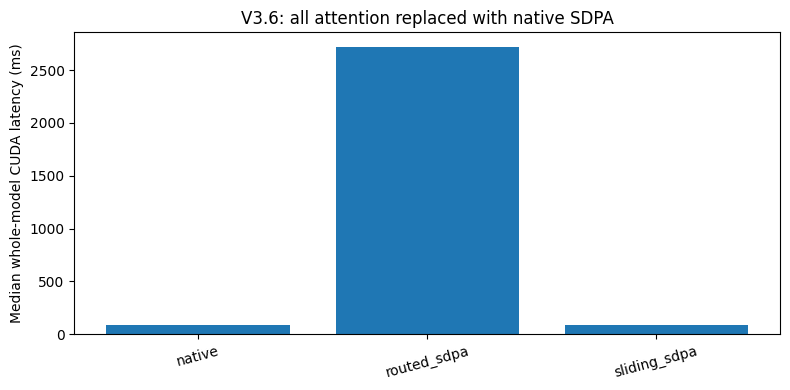

In [10]:
#@title 10. Save report, stop/go verdict, plot
from datetime import datetime,timezone
gates={}
for mode,row in reports.items():
    q=row["quality"]
    cosines=[r[mode]["quality"]["cosine"] for r in isolated.values()]
    gates[mode]=dict(
        agreement_ge_95=q["teacher_agreement"]>=.95,
        gold_drop_le_1pp=q["gold_accuracy_drop"]<=.01,
        isolated_cosine_ge_95=min(cosines)>=.95,
        actual_speedup=row["speedup"]>1
    )
    gates[mode]["ready"]=all(gates[mode].values())
report=dict(
    version="V3.6-all-attention-native-sdpa",
    created_utc=datetime.now(timezone.utc).isoformat(),
    model=SOURCE_MODEL,
    gpu=torch.cuda.get_device_name(0),torch=torch.__version__,
    seed=SEED,official_test_used=False,
    dataset="LocalLLaMA/typed-decisions all TRAIN, disjoint cases",
    full_layers=FULL_LAYERS,sliding_layers=SLIDING_LAYERS,
    selected_sliding_window=selected_window,
    sliding_window_probe=window_probe,
    routed_parameters=dict(block_size=BLOCK_SIZE,route_blocks=ROUTE_BLOCKS,
                           remote_top_k=REMOTE_K,local_left=LOCAL_LEFT,
                           local_right=LOCAL_RIGHT,query_chunk=QUERY_CHUNK),
    pretrained_projections_unchanged=True,
    both_variants_use_native_sdpa=True,
    isolated=isolated,variants=reports,gates=gates,
    notes=[
        "Both variants replace pretrained full AND sliding layers.",
        "Native SDPA with a custom sliding mask may still use dense GPU work.",
        "Routed SDPA uses an actual unified SDPA over selected original keys.",
        "No oracle key retrieval, finetuning or published checkpoint.",
        "The official dataset TEST split is not used.",
        "200 decisions is a small audit and not proof of equal quality.",
    ]
)
save=OUTPUT_DIR/"v36_all_attention_routed_vs_sliding_native_sdpa.json"
save.write_text(json.dumps(report,indent=2),encoding="utf-8")
print("Saved",save)
for name,row in reports.items():
    print(name,"accuracy",row["quality"]["student_gold_accuracy"],
          "teacher agreement",row["quality"]["teacher_agreement"],
          "latency",row["new_model_ms"],"ms","speedup",row["speedup"],
          "passed",gates[name])
import matplotlib.pyplot as plt
names=["native"]+list(reports)
times=[native_median]+[v["new_model_ms"] for v in reports.values()]
plt.figure(figsize=(8,4))
plt.bar(names,times)
plt.ylabel("Median whole-model CUDA latency (ms)")
plt.title("V3.6: all attention replaced with native SDPA")
plt.xticks(rotation=15)
plt.tight_layout();plt.show()
